## Importo posibles librerías

In [1]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## ANÁLISIS 2 - Análisis del rendimiento según el género

Vamos a estudiar si existen diferencias en el rendimiento académico entre hombres y mujeres, en cada competencia.

In [2]:
sp = pd.read_csv("../data/StudentsPerformance_depurado.csv", sep =",")

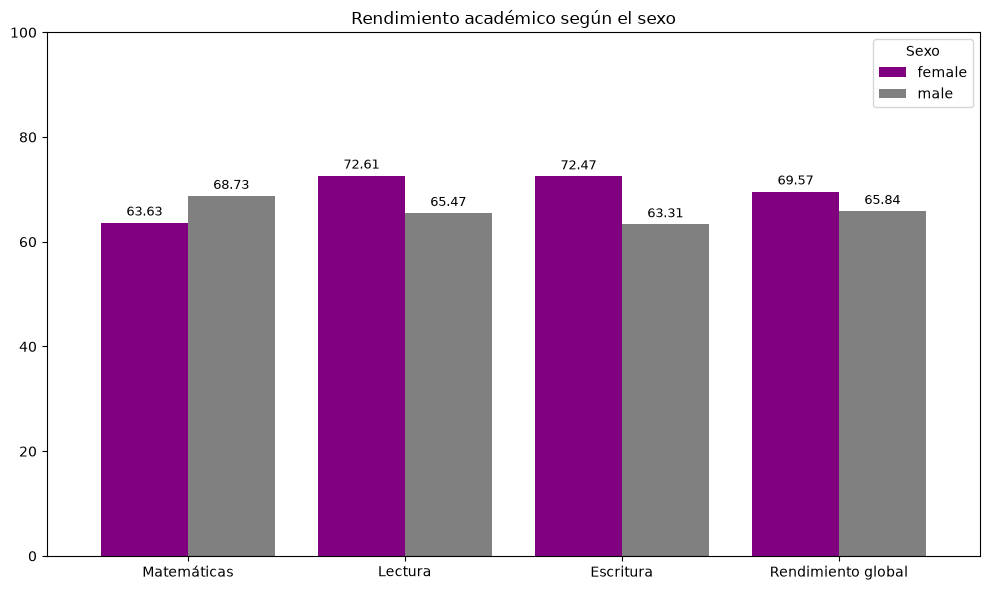

In [3]:
rendimiento_sexo = sp.groupby("gender")[["math_score", "reading_score", "writing_score", "global_score"]].mean()

rendimiento_sexo = rendimiento_sexo.T #trasponer los datos para poder sacar el gráfico que quiero

rend = rendimiento_sexo.plot(kind="bar", figsize=(10, 6), width=0.8, color=["purple", "grey"])

plt.title("Rendimiento académico según el sexo")
plt.xticks(ticks=range(4), labels=["Matemáticas", "Lectura", "Escritura", "Rendimiento global"], rotation=0)

for container in rend.containers:
    rend.bar_label(container, fmt="%.2f", padding=3, fontsize=9)

plt.ylim(0, 100)
plt.legend(title="Sexo")

plt.tight_layout()

plt.savefig("../img/Grafico_2_1.jpg", dpi=300, bbox_inches="tight")

plt.show()

El gráfico evidencia que existen diferencias entre mujeres y hombres en cada competencia. Pero, ¿Son estadísticamente significativas? Para ello vamos a usar la libreria "scipy" con el módulo "stats" y concretamemte la función "ttest_ind", que corresponde a la prueba t-Student para muestras independientes:

    Hipótesis nula (H₀): no existen diferencias entre las puntuaciones medias de mujeres y hombres.
    Hipótesis alternativa (H₁): existen diferencias entre las puntuaciones medias de mujeres y hombres.

Si p-valor inferior a 0,05 : "Significativo"
    Rechazamos la hipótesis nula. Tenemos evidencia estadística de que las medias son diferentes.
    
Si p-valor igual o superior a 0,05: "No significativo"
    No rechazamos la hipótesis nula. No tenemos evidencia suficiente para afirmar que las medias sean diferentes.

Para poder calcularlo, asumimos muestras independientes sin igualdad de varianzas.

In [4]:
from scipy.stats import ttest_ind

In [5]:
variables = ["math_score", "reading_score", "writing_score", "global_score"]

for variable in variables:

    mujeres = sp[sp["gender"] == "female"][variable]
    hombres = sp[sp["gender"] == "male"][variable]

    t, p = ttest_ind(mujeres, hombres, equal_var=False)

    print("\n", variable)
    print("Estadístico t:", round(t, 4))
    print("p-valor:", round(p, 4))

    if p < 0.05:
        print("Existe una diferencia estadísticamente significativa")
    else:
        print("No existe una diferencia estadísticamente significativa")


 math_score
Estadístico t: -5.398
p-valor: 0.0
Existe una diferencia estadísticamente significativa

 reading_score
Estadístico t: 7.9684
p-valor: 0.0
Existe una diferencia estadísticamente significativa

 writing_score
Estadístico t: 9.9977
p-valor: 0.0
Existe una diferencia estadísticamente significativa

 global_score
Estadístico t: 4.1791
p-valor: 0.0
Existe una diferencia estadísticamente significativa


Los resultados confirman que las diferencias son estadísticamente significativas. Vemos que los hombres destacan en Matemáticas, mientras que las mujeres obtienen mejores resultados en Lectura y Escritura. En el rendimiento global también presentan una media superior las mujeres.

Esto demuestra que hay diferencias estadísticas entre los grupos de la muestra, pero no demuestra que el sexo sea la causa de esas diferencias.